# แบบฝึกหัด IQR : Anomaly Detection

IQR = Q3 − Q1 · รั้วล่าง = Q1 − k·IQR · รั้วบน = Q3 + k·IQR · k = 1.5 (outlier) หรือ 3 (extreme outlier)


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## ข้อ 1 · คำนวณ IQR และรั้ว (20 คะแนน)

ปริมาณน้ำที่บ้านหลังหนึ่งใช้ต่อวัน 15 วัน

1. ใช้ `np.percentile` หา Q1, Q3, IQR และรั้วล่าง/รั้วบน (k = 1.5)
2. แสดงค่าที่อยู่นอกรั้ว

In [5]:
water = np.array([182, 175, 190, 168, 185, 178, 420, 181, 172, 188, 176, 95, 183, 179, 186], float)  # ลิตร/วัน 15 วัน

# TODO 1.1–1.2
q1=np.percentile(water,25)
q3=np.percentile(water,75)
iqr=q3-q1
lo=q1-1.5*iqr
hi=q3+1.5*iqr
mask=(water<lo)|(water>hi)
print('Q1:',q1)
print(f'Q3:{q3} IQR:{iqr} Lower:{lo} Upper:{hi}')
print(water[mask])



Q1: 175.5
Q3:185.5 IQR:10.0 Lower:160.5 Upper:200.5
[420.  95.]


## ข้อ 2 · เขียนฟังก์ชัน `iqr_outliers` (20 คะแนน)

1. เขียนฟังก์ชันรับ `x` และ `k=1.5` คืนค่า `(mask, lo, hi)` โดย `mask` เป็น boolean array ว่าค่าใดอยู่นอกรั้ว
2. ใช้กับยอดขาย 18 วัน ที่ k = 1.5 และ k = 3 · ค่าใดเป็น outlier ทั่วไป ค่าใดเป็น extreme outlier
3. ทดสอบด้วย `assert` อย่างน้อย 2 กรณี เช่น ข้อมูลไม่มี outlier ต้องได้ mask เป็น False ทั้งหมด

In [13]:
def iqr_outliers(x, k=1.5):
  x=np.asarray(x,float)
  q1,q3=np.percentile(x,[25,75])
  iqr=q3-q1
  lo=q1-k*iqr
  hi=q3+k*iqr
  mask=(x<lo)|(x>hi)
  return mask,lo,hi
  pass

sales = np.array([52, 48, 55, 61, 47, 50, 53, 49, 58, 51, 120, 54, 46, 79, 50, 57, 30, 52], float)  # ยอดขาย (พันบาท) 18 วัน

# TODO 2.2
for k in [1.5,3]:
  mask,lo,hi = iqr_outliers(sales,k)
  print(f'k={k} mask={mask.all()} lo={lo} hi={hi}')

# TODO 2.3 assert
assert iqr_outliers([10,11,12,13,14,15,16,17,18,19,100])[0].tolist()==[False]*10+[True]
assert not iqr_outliers([10,11,12,13,14,15,16,17,18,19])[0].any()
print('ผ่านทุก assert' )

k=1.5 mask=False lo=38.375 hi=67.375
k=3 mask=False lo=27.5 hi=78.25
ผ่านทุก assert


## ข้อ 3 · Boxplot กับรั้ว IQR (20 คะแนน)

1. วาด boxplot ของ `sales` ด้วย `plt.boxplot(sales, whis=1.5)` แล้วเก็บผลที่ return ไว้ในตัวแปร
2. วาดเส้นแนวนอนที่รั้วล่างและรั้วบนจากข้อ 2 ทับลงบนกราฟ
3. ดึงค่าปลายหนวด (`['whiskers']`) และจุด flier (`['fliers']`) ออกมา เทียบกับผลของ `iqr_outliers`

**คำถาม:** ปลายหนวดอยู่ที่รั้วพอดีหรือไม่ ถ้าไม่ อยู่ที่ไหน

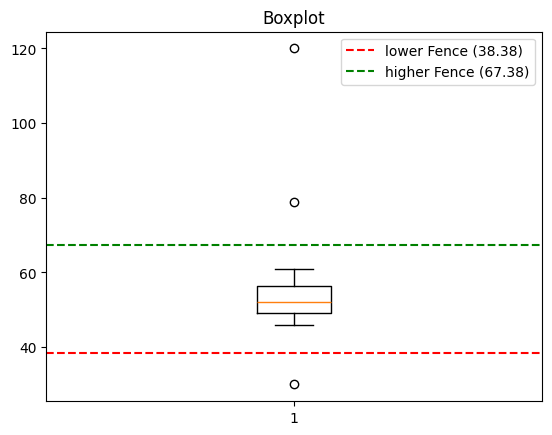

รั้ว (Fences):       lo = 38.375, hi = 67.375
ปลายหนวด (Whiskers): lo = 46.0, hi = 61.0
จุด Fliers จากกราฟ:  [ 30. 120.  79.]
Outliers จากฟังก์ชัน: [120.  79.  30.]


In [14]:
# TODO ข้อ 3
SalesBP = plt.boxplot(sales,whis=1.5)
mask, lo, hi = iqr_outliers(sales, k=1.5)

plt.axhline(lo, color='red', linestyle='--', label=f'lower Fence ({lo:.2f})')
plt.axhline(hi, color='green', linestyle='--', label=f'higher Fence ({hi:.2f})')
plt.legend()
plt.title('Boxplot')
plt.show()

lo_whisker = SalesBP['whiskers'][0].get_ydata()[1]
hi_whisker = SalesBP['whiskers'][1].get_ydata()[1]
fliers = SalesBP['fliers'][0].get_ydata()
า่
print(f'รั้ว (Fences):       lo = {lo:.3f}, hi = {hi:.3f}')
print(f'ปลายหนวด (Whiskers): lo = {lo_whisker}, hi = {hi_whisker}')
print(f'จุด Fliers จากกราฟ:  {fliers}')
print(f'Outliers จากฟังก์ชัน: {sales[mask]}')

ปลายหนวดไม่อยู่ที่รั้วพอดีแต่จะหดเข้ามาหยุดอยู่ที่ ค่าข้อมูลจริงที่อยู่ใกล้รั้วที่สุดแต่ยังไม่หลุดออกนอกรั้วจากการคำนวณกับข้อมูล sales ชุดนี้ ($Q_1 = 49.25$, $Q_3 = 56.5$, $IQR = 7.25$):รั้วล่าง (lo) อยู่ที่ 38.375 แต่ ปลายหนวดล่าง อยู่ที่ 46.0 (ค่าข้อมูลจริงที่น้อยที่สุดซึ่งยังมากกว่าหรือเท่ากับ 38.375)รั้วบน (hi) อยู่ที่ 67.375 แต่ ปลายหนวดบน อยู่ที่ 61.0 (ค่าข้อมูลจริงที่มากที่สุดซึ่งยังน้อยกว่าหรือเท่ากับ 67.375)ส่วนค่าที่หลุดรั้วออกไปคือ [30.0, 79.0, 120.0] จะถูกแสดงเป็นจุด Fliers ซึ่งตรงกับผลลัพธ์ของ sales[mask] พอดี

## ข้อ 4 · IQR รายกลุ่ม (contextual anomaly) (20 คะแนน)

ค่าจ้างรายเดือน (พันบาท) ของพนักงาน 3 อาชีพ อาชีพละ 8 คน

1. ใช้ `iqr_outliers` กับค่าจ้างทั้ง 24 คนรวมกัน พบ outlier กี่คน
2. ใช้ `groupby('occupation')` คำนวณ IQR แยกแต่ละอาชีพ (ใช้ `.transform` ได้) พบ outlier คนใด
3. ทำตาราง Q1, Q3, IQR, รั้วล่าง, รั้วบน ของแต่ละอาชีพ
4. อธิบายว่าทำไมผลรวมกับผลรายกลุ่มต่างกัน

In [16]:
wage = pd.DataFrame({
    'occupation': ['cleaner']*8 + ['clerk']*8 + ['engineer']*8,
    'wage_k': [12,13,12,14,13,12,15,35,  18,20,19,22,21,20,23,9,  60,65,58,70,62,66,64,61]})

# TODO 4.1
mask_all, lo_all, hi_all = iqr_outliers(wage['wage_k'])
print(f"4.1 รวมทั้ง 24 คน: lo={lo_all:.2f}, hi={hi_all:.2f}, พบ outlier = {mask_all.sum()} คน")
# TODO 4.2
wage['is_outlier'] = wage.groupby('occupation')['wage_k'].transform(lambda s: iqr_outliers(s)[0])
print("\n4.2 รายชื่อ outlier แยกตามอาชีพ:")
print(wage[wage['is_outlier']])
# TODO 4.3
def group_stats(s):
    q1, q3 = np.percentile(s, [25, 75])
    iqr = q3 - q1
    return pd.Series({
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'รั้วล่าง (lo)': q1 - 1.5 * iqr,
        'รั้วบน (hi)': q3 + 1.5 * iqr
    })

summ = wage.groupby('occupation')['wage_k'].apply(group_stats).unstack()
print("\n4.3 สรุป IQR และรั้วของแต่ละอาชีพ:")
display(summ)

4.1 รวมทั้ง 24 คน: lo=-56.00, hi=130.00, พบ outlier = 0 คน

4.2 รายชื่อ outlier แยกตามอาชีพ:
   occupation  wage_k  is_outlier
7     cleaner      35        True
15      clerk       9        True

4.3 สรุป IQR และรั้วของแต่ละอาชีพ:


,Q1,Q3,IQR,รั้วล่าง (lo),รั้วบน (hi)
occupation,,,,,
cleaner,12.00,14.25,2.25,8.625,17.625
clerk,18.75,21.25,2.50,15.000,25.000
engineer,60.75,65.25,4.50,54.000,72.000


**4.4**
เมื่อนำข้อมูลทั้ง 3 อาชีพมารวมกัน ฐานเงินเดือนของแต่ละอาชีพต่างกันมาก (cleaner อยู่ช่วง ~12–15 ส่วน engineer อยู่ช่วง ~58–70) ทำให้ค่าการกระจายตัวรวม (IQR = 46.5) กว้างเกินจริง จนรั้วล่างและรั้วบนถ่างออกไปถึง [-56, 130] ส่งผลให้ค่าที่ผิดปกติในบริบทของอาชีพตัวเองถูกกลืนหายไป (เกิดอาการ Masking)   แต่พอแยกคำนวณตามอาชีพ (Contextual Anomaly) ค่า IQR ของแต่ละกลุ่มจะแคบและสะท้อนฐานเงินเดือนจริงของอาชีพนั้น ๆ ทำให้จับได้ทันทีว่า cleaner ที่ได้ 35 พันบาท (สูงกว่าเพื่อนร่วมอาชีพเกือบ 3 เท่า) และ clerk ที่ได้ 9 พันบาท (ต่ำกว่าเพื่อนร่วมอาชีพครึ่งหนึ่ง) คือค่าผิดปกติในกลุ่มของตัวเอง